<a href="https://colab.research.google.com/github/kredd2506/hyouka/blob/cloud-session/notebooks/nrx_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# nrx-jax: cloud session on Colab

Runs the GPU half of the project: exact pilots, XLA GPU latency and compiler walk (TF32 and true fp32), TensorRT (fp32 / TF32 / fp16) on the same GPU, full BLER sweep, and training from scratch.

**Session 1 (L4) already did:** exact pilots, the full sweep (acceptance met), XLA latency in TF32, 5k training steps. Defaults below now skip the sweep and resume training from the 5k checkpoint on Drive.

**Before you start**
1. *Runtime → Change runtime type → GPU.* A100 or L4 is best. T4 works but is slower (fp32 ≈ 8 TFLOP/s).
2. Set the options in the next cell.
3. Run all cells (*Runtime → Run all*). Each section prints a short result.

**If Colab disconnects:** re-run sections 0–2 (setup, ~3 min), then continue where you stopped. Training resumes from its last checkpoint on Google Drive.

| Section | GPU time (A100 / T4, rough) |
|---|---|
| 0–2 Setup + tests | 3–5 min |
| 3 Exact pilots | < 1 min |
| 4 XLA latency + compiler walk | 2–5 min |
| 5 TensorRT | 3–10 min |
| 6 Full BLER sweep | 30–90 min |
| 7 Training, 30k steps | 1–4 h |
| 8 Trained-model sweep | 10–30 min |

In [3]:
# ---- Options ----
REPO_URL     = "https://github.com/kredd2506/hyouka.git"
BRANCH       = "cloud-session"
USE_DRIVE    = True      # keep checkpoints + results on Google Drive (needed to resume after a disconnect)
RUN_TRT      = True      # section 5
RUN_SWEEP    = False     # section 6 (long; done in session 1)
RUN_TRAIN    = True      # sections 7-8 (longest)
TRAIN_STEPS  = 30000     # notebook reference; e.g. 5000 for a quick run
PUSH_RESULTS = False     # section 9: needs a GH_TOKEN Colab secret with write access

## 0. Hardware and storage

In [4]:
import os, re, subprocess, pathlib

def sh(cmd):
    return subprocess.run(cmd, shell=True, capture_output=True, text=True).stdout.strip()

gpu = sh("nvidia-smi --query-gpu=name,driver_version,memory.total --format=csv,noheader")
ACCEL = "gpu" if gpu else ("tpu" if pathlib.Path("/dev/accel0").exists() or "COLAB_TPU_ADDR" in os.environ else "cpu")
print("accelerator:", ACCEL, "|", gpu or "no NVIDIA GPU")

if ACCEL == "gpu":
    driver_major = int(gpu.split(",")[1].strip().split(".")[0])
    # torch 2.15 / jax[cuda13] need CUDA 13 -> driver >= 580. Older drivers: torch 2.14.1+cu126 and jax[cuda12].
    CUDA_MODE = "cuda13" if driver_major >= 580 else "cuda12"
    print(f"driver {driver_major} -> {CUDA_MODE}")
else:
    CUDA_MODE = None
    print("No GPU: sections 3, 5, 6, 7, 8 are skipped. TPU runs sections 4 only.")

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = pathlib.Path("/content/drive/MyDrive/nrx-jax")
else:
    OUT = pathlib.Path("/content/nrx-jax-out")
OUT.mkdir(parents=True, exist_ok=True)
RUN_DIR = OUT / "run1"
print("outputs ->", OUT)

accelerator: gpu | NVIDIA L4, 580.82.07, 23034 MiB
driver 580 -> cuda13
Mounted at /content/drive
outputs -> /content/drive/MyDrive/nrx-jax


## 1. Get the code
Clones `BRANCH` from GitHub. For a private repo, add a Colab secret `GH_TOKEN` (key icon in the left bar). Alternatively upload a `hyouka.bundle` (from `git bundle create hyouka.bundle main cloud-session`) to `/content`.

In [5]:
REPO = pathlib.Path("/content/hyouka")
if not REPO.exists():
    bundle = pathlib.Path("/content/hyouka.bundle")
    if bundle.exists():
        url = str(bundle)
    else:
        url = REPO_URL
        try:
            from google.colab import userdata
            tok = userdata.get("GH_TOKEN")
            url = REPO_URL.replace("https://", f"https://{tok}@")
        except Exception:
            pass
    r = subprocess.run(f"git clone -q -b {BRANCH} {url} {REPO}", shell=True, capture_output=True, text=True)
    print(r.stderr.replace(url, REPO_URL) or "cloned")
%cd /content/hyouka
!git log --oneline -3

cloned
/content/hyouka
cf17d50 (HEAD -> cloud-session, origin/cloud-session) Session 2 results; fix TRT install target env, GPU parity test, resume-at-end assert
a34a646 Created using Colab
f0504d2 Fix TensorRT install, add fp32/TF32 control, ablation-based GPU breakdown


## 2. Environment
`uv` installs Python 3.12 and the exact versions in `uv.lock`, separate from Colab's own Python.

In [6]:
!pip -q install uv
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"   # let Sionna's torch share the GPU with JAX
if CUDA_MODE == "cuda13":
    !uv sync -q --extra cuda
elif CUDA_MODE == "cuda12":
    !uv sync -q
    !uv pip install -q --reinstall "torch==2.14.1" --index-url https://download.pytorch.org/whl/cu126
    !uv pip install -q "jax[cuda12]==0.12.1"
elif ACCEL == "tpu":
    !uv sync -q --extra tpu
else:
    !uv sync -q
os.environ["UV_NO_SYNC"] = "1"   # stop `uv run` from reverting the CUDA-specific installs to uv.lock

!make host-info
!make test

Sun Nov 22 01:24:13 AM UTC 2026
Linux bad0ba974a39 6.6.159+ #1 SMP Thu Oct 22 03:07:54 UTC 2026 x86_64 x86_64 x86_64 GNU/Linux
Sun Nov 22 01:24:13 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   37C    P8             12W /   72W |       0MiB /  23034MiB |      0%      Default |
|            

In [7]:
# Sanity: both frameworks see the accelerator.
!uv run python -c "import jax, torch, sionna.phy; print('jax', jax.devices()); print('torch cuda', torch.cuda.is_available()); print('sionna device', sionna.phy.config.device)" 2>&1 | grep -v jitc

jax [CudaDevice(id=0)]
torch cuda True
sionna device cuda:0


## 3. Exact training pilots (CUDA RNG, seed 42)
The pre-trained weights were trained with pilots drawn from the CUDA RNG. The repo ships pilots recovered from the weights; this regenerates the exact ones and counts mismatches.

In [8]:
if ACCEL == "gpu":
    !make pilots-cuda 2>&1 | grep -v jitc | tail -2

uv run python -m nrx.pilots compare assets/pilots_recovered.npy assets/pilots_cuda_seed42.npy
0/232 pilots differ


## 4. XLA on this accelerator: latency + compiler walk
Same script and fixtures as on the laptop. The deadline is judged on p99 batch latency (B users in one slot).

Run twice: `default` precision (XLA allows TF32 convs on Ampere/Ada) and `highest` (true fp32). The time breakdown now ablates parts of the full compiled graph, because isolated-op timings on GPU are mostly dispatch overhead.

In [9]:
for prec in ["default", "highest"]:
    !make backends PRECISION={prec} 2>&1 | grep -v jitc | tail -4
    !make compiler PRECISION={prec} 2>&1 | grep -v jitc | grep -E "^## 3|^  fusion|^## 5|^  (full|without|dispatch|⇒)"

slot budget 0.5 ms @ 30 kHz SCS, judged on p99 batch latency
     gpu default B=1    p99     0.869 ms  max|dLLR| 2.1e-05  (misses)
     gpu default B=8    p99     2.067 ms  max|dLLR| 9.0e-03  (misses)
     gpu default B=128  p99    44.197 ms  max|dLLR| 1.6e-02  (misses)
## 3. Optimized HLO: 60 kernels launched per call
  fusion:kCustom×32, fusion:kInput×25, fusion:kLoop×3
## 5. Where the time goes (ablation inside the full compiled graph, median ms)
  full NRX                                0.803
  without LayerNorm                       0.711
  without the 8 residual convs            0.340
  without both (in/out conv + glue)       0.223
  dispatch floor (jit x+1)                0.085
  ⇒ 8 residual convs ≈ 0.464 ms (58%), 8 LayerNorms ≈ 0.092 ms (11%), dispatch ≈ 11% of a call
## 3. Optimized HLO: 85 kernels launched per call
  fusion:kInput×49, fusion:kLoop×28, fusion:kCustom×8
## 5. Where the time goes (ablation inside the full compiled graph, median ms)
  full NRX                  

## 5. TensorRT on the same GPU
ONNX export of the torch reference → TensorRT engines in three modes: **fp32** (TF32 off, compare with XLA `highest`), **tf32** (compare with XLA `default`), **fp16**. Same timing method and fixtures as XLA.

The `tensorrt` wrapper on PyPI is a source package that failed to install in session 1; `make trt-install` takes the prebuilt libs + bindings wheels from NVIDIA's index instead.

In [10]:
if ACCEL == "gpu" and RUN_TRT:
    trt_cuda = "cu13" if CUDA_MODE == "cuda13" else "cu12"
    !make trt-install TRT_CUDA={trt_cuda} 2>&1 | grep -v jitc | tail -3
    !make onnx 2>&1 | grep -v jitc | grep "^B="
    !make trt 2>&1 | grep -v jitc | grep -E "^TensorRT|skipped|Error|p99"

 + tensorrt-cu13-libs==11.5.0.63
UV_NO_SYNC=1 uv run python -c "import tensorrt_bindings as t; print('TensorRT', t.__version__)"
TensorRT 11.5.0.63
B=1    results/onnx/nrx_b1.onnx  19.5 MB  LLR_ort - LLR_torch: max 1.18e-04, rms 3.36e-05
B=8    results/onnx/nrx_b8.onnx  19.5 MB  LLR_ort - LLR_torch: max 1.75e-04, rms 3.71e-05
B=128  results/onnx/nrx_b128.onnx  19.5 MB  LLR_ort - LLR_torch: max 2.94e-04, rms 4.43e-05
TensorRT 11.5.0.63 (tensorrt_bindings), NVIDIA L4
{"backend": "tensorrt", "precision": "fp32", "device": "NVIDIA L4", "trt": "11.5.0.63", "torch": "2.15.0+cu132", "batch": 1, "build_s": 3.68, "p50_ms": 0.5349, "p99_ms": 0.5468, "iters": 1000, "per_user_ms": 0.5349, "max_abs_llr_err": 5.341e-05, "rms_llr_err": 2.936e-06}
{"backend": "tensorrt", "precision": "fp32", "device": "NVIDIA L4", "trt": "11.5.0.63", "torch": "2.15.0+cu132", "batch": 8, "build_s": 3.24, "p50_ms": 2.8913, "p99_ms": 2.9948, "iters": 901, "per_user_ms": 0.3614, "max_abs_llr_err": 4.005e-05, "rms_llr_err"

## 6. Full BLER sweep (notebook settings, `max_mc_iter=1000`)
JAX port, torch reference, and both baselines. Resolves BLER 1e-4 (acceptance: ported within 0.2 dB of the notebook). If section 3 found mismatched pilots, a second sweep with the exact CUDA pilots runs too.

In [11]:
if ACCEL == "gpu" and RUN_SWEEP:
    !make sweep 2>&1 | grep -v jitc | tail -9
    n_diff = sh("cd /content/hyouka && uv run python -m nrx.pilots compare assets/pilots_recovered.npy assets/pilots_cuda_seed42.npy 2>/dev/null | grep -o '^[0-9]*'")
    if n_diff and int(n_diff) > 0:
        print(f"{n_diff} pilots differ -> sweeping NRX with exact CUDA pilots")
        !NRX_PILOTS=assets/pilots_cuda_seed42.npy uv run python -m nrx.evaluate --systems jax-ported --out results/ber_bler_ported_cudapilots.csv 2>&1 | grep -v jitc | tail -4

## 7. Train from scratch in JAX
Checkpoints every 1k steps to Drive. After a disconnect, re-run sections 0–2 and this cell; it resumes. Session 1 left a 5k-step checkpoint in `MyDrive/nrx-jax/run1`, so this continues from there (~70 min on an L4 for the remaining 25k). `wait_ms` in `train_log.csv` shows if Sionna data generation is the bottleneck.

In [12]:
if ACCEL == "gpu" and RUN_TRAIN:
    !make train RUN={RUN_DIR} STEPS={TRAIN_STEPS} 2>&1 | grep -v jitc | grep -E "step|resumed|Error|assert"

uv run python -m nrx.train --steps 30000 --ckpt-dir /content/drive/MyDrive/nrx-jax/run1
resumed from step 30000


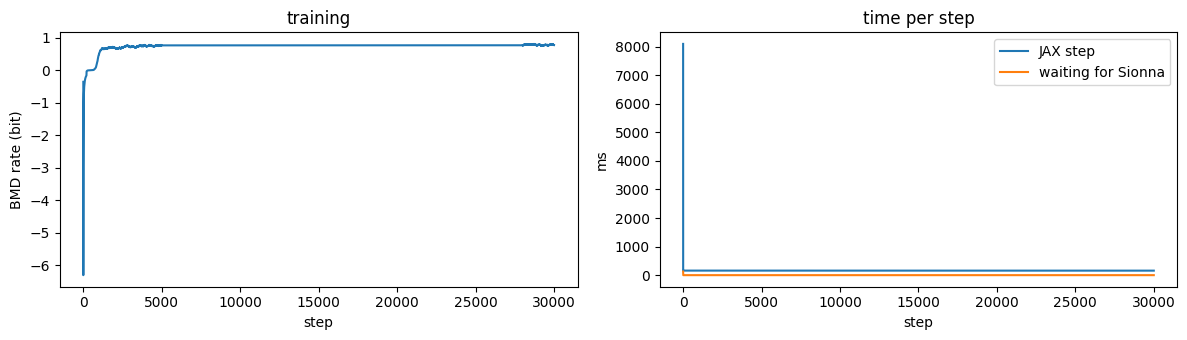

steps 7000, final rate 0.7865, median step 159.0 ms, median wait 0.0 ms


In [13]:
# Training curve
import pandas as pd, matplotlib.pyplot as plt
log = RUN_DIR / "train_log.csv"
if log.exists():
    df = pd.read_csv(log)
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    ax[0].plot(df.step, df.rate.rolling(200, min_periods=1).mean()); ax[0].set(xlabel="step", ylabel="BMD rate (bit)", title="training")
    ax[1].plot(df.step, df.step_ms.rolling(200, min_periods=1).median(), label="JAX step"); ax[1].plot(df.step, df.wait_ms.rolling(200, min_periods=1).median(), label="waiting for Sionna")
    ax[1].set(xlabel="step", ylabel="ms", title="time per step"); ax[1].legend()
    plt.tight_layout(); plt.savefig("results/train_curve.png", dpi=120); plt.show()
    print(f"steps {len(df)}, final rate {df.rate.tail(500).mean():.4f}, median step {df.step_ms.median():.1f} ms, median wait {df.wait_ms.median():.1f} ms")

## 8. Evaluate the trained model

In [14]:
if ACCEL == "gpu" and RUN_TRAIN:
    !make eval-trained RUN={RUN_DIR} 2>&1 | grep -v jitc | tail -6


system                        @1e-1      @1e-2      @1e-3      @1e-4
baseline-perfect-csi (nb)      -1.71      -1.30      -0.71       0.55
baseline-ls-estimation (nb)       2.16       2.58       3.36       5.05
neural-receiver (nb)          -1.53      -1.03       0.14       2.21
jax-trained                   -1.50      -1.01       0.23       2.43


## 9. Summary and save

In [15]:
import json, pandas as pd
R = pathlib.Path("results")

def jsonl(p):
    return pd.DataFrame([json.loads(l) for l in open(p)]) if p.exists() else pd.DataFrame()

xla = jsonl(R / "backend_latency.jsonl")
trt = jsonl(R / "trt_latency.jsonl")
rows = []
if not xla.empty:
    for _, r in xla[xla.backend != "cpu"].iterrows():
        prec = r.get("precision", "default")
        prec = "tf32 (xla default)" if prec in ("default", None) or prec != prec else f"fp32 (xla {prec})"
        rows.append(dict(stack=f"XLA {r.backend} (jax {r.jax})", precision=prec, B=r.batch, p50_ms=r.p50_ms, p99_ms=r.p99_ms, max_llr_err=r.max_abs_llr_err))
if not trt.empty:
    for _, r in trt.iterrows():
        rows.append(dict(stack=f"TensorRT {r.trt}", precision=r.precision, B=r.batch, p50_ms=r.p50_ms, p99_ms=r.p99_ms, max_llr_err=r.max_abs_llr_err))
if rows:
    print("Latency, same GPU, same fixtures (deadline 0.5 ms on p99):")
    table = pd.DataFrame(rows).drop_duplicates(["stack", "precision", "B"], keep="last")  # latest run per setting
    display(table.sort_values(["B", "stack", "precision"]).reset_index(drop=True))

!uv run python -m nrx.evaluate --summary results/reference.csv results/ber_bler_ported.csv results/ber_bler_ported_cudapilots.csv results/ber_bler_trained.csv 2>&1 | grep -v jitc

Latency, same GPU, same fixtures (deadline 0.5 ms on p99):


,stack,precision,B,p50_ms,p99_ms,max_llr_err
0,TensorRT 11.5.0.63,fp32,1,0.5349,0.5468,0.000053
1,TensorRT 11.5.0.63,tf32,1,0.5399,0.5530,0.000053
2,XLA METAL (jax 0.4.34),tf32 (xla default),1,1.2540,1.3440,0.000037
3,XLA gpu (jax 0.12.1),fp32 (xla highest),1,0.8020,0.8670,0.000018
4,XLA gpu (jax 0.12.1),tf32 (xla default),1,0.8050,0.8690,0.000021
5,TensorRT 11.5.0.63,fp32,8,2.8913,2.9948,0.000040
6,TensorRT 11.5.0.63,tf32,8,1.7877,1.8549,0.009435
7,XLA METAL (jax 0.4.34),tf32 (xla default),8,5.1180,6.3830,0.000046
8,XLA gpu (jax 0.12.1),fp32 (xla highest),8,2.8860,3.0100,0.000032
9,XLA gpu (jax 0.12.1),tf32 (xla default),8,1.8500,2.0670,0.009034


file:system                                    @1e-02   @1e-03   @1e-04
reference:baseline-perfect-csi                  -1.30    -0.71     0.55
reference:baseline-ls-estimation                 2.58     3.36     5.05
reference:neural-receiver                       -1.03     0.14     2.21
ber_bler_ported:jax-ported                      -1.03     0.21     2.33
ber_bler_ported:torch-ref                       -1.03     0.21     2.33
ber_bler_ported:baseline-perfect-csi            -1.30    -0.64     0.38
ber_bler_ported:baseline-ls-estimation           2.54     3.44     5.00
ber_bler_ported_cudapilots:jax-ported           -1.05     0.23     2.41
ber_bler_trained:jax-trained                    -1.01     0.23     2.43


In [16]:
# Save everything to Drive (or /content) and offer a zip download.
import shutil, time
stamp = time.strftime("%Y%m%d-%H%M")
dest = OUT / f"results-{stamp}"
shutil.copytree("results", dest, ignore=shutil.ignore_patterns("*.onnx"))
for f in ["assets/pilots_cuda_seed42.npy"]:
    if pathlib.Path(f).exists(): shutil.copy(f, dest)
if (RUN_DIR / "train_log.csv").exists(): shutil.copy(RUN_DIR / "train_log.csv", dest)
shutil.make_archive(f"/content/nrx-results-{stamp}", "zip", dest)
print("saved", dest)
from google.colab import files
files.download(f"/content/nrx-results-{stamp}.zip")

saved /content/drive/MyDrive/nrx-jax/results-20261122-0152


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
# Optional: commit results to the cloud-session branch.
if PUSH_RESULTS:
    from google.colab import userdata
    tok = userdata.get("GH_TOKEN")
    if (RUN_DIR / "train_log.csv").exists():
        shutil.copy(RUN_DIR / "train_log.csv", "results/train_log.csv")
    msg = f"Cloud results: Colab {gpu.split(',')[0] if gpu else ACCEL}"
    push_url = REPO_URL.replace("https://", f"https://{tok}@")
    !git config user.name "nrx-colab" && git config user.email "nrx-colab@users.noreply.github.com"
    !git add results assets && git commit -qm "$msg"
    r = subprocess.run(f"git push -q {push_url} HEAD:{BRANCH}", shell=True, capture_output=True, text=True)
    print((r.stderr or "pushed").replace(tok, "***"))